In [1]:
%pip install -q numpy matplotlib


In [2]:
csv = """Method,Score
A,60
A,65
A,70
A,68
A,72
B,75
B,80
B,77
B,82
B,76
"""
with open("teaching_methods.csv", "w") as f:
    f.write(csv)
print("Created", "teaching_methods.csv")


Created teaching_methods.csv


Mean of Method A : 67.0
Mean of Method B : 78.0
Observed difference = 11.0
p-value = 0.009
Reject H0: there is a significant difference between the two teaching methods.


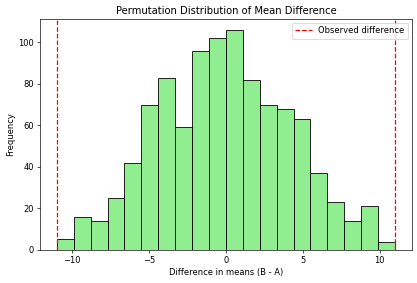

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
A = np.array([60, 65, 70, 68, 72])
B = np.array([75, 80, 77, 82, 76])

observed_diff = np.mean(B) - np.mean(A)
print("Mean of Method A :", np.mean(A))
print("Mean of Method B :", np.mean(B))
print("Observed difference =", observed_diff)

combined = np.concatenate([A, B])
perm_diffs = []
for _ in range(1000):
    shuffled = np.random.permutation(combined)
    new_A = shuffled[:len(A)]
    new_B = shuffled[len(A):]
    perm_diffs.append(np.mean(new_B) - np.mean(new_A))
perm_diffs = np.array(perm_diffs)

p_value = np.mean(np.abs(perm_diffs) >= abs(observed_diff))
print("p-value =", p_value)

if p_value < 0.05:
    print("Reject H0: there is a significant difference between the two teaching methods.")
else:
    print("Fail to reject H0: no significant difference between the two teaching methods.")

plt.figure(figsize=(8, 5))
plt.hist(perm_diffs, bins=20, color="lightgreen", edgecolor="black")
plt.axvline(observed_diff, color="red", linestyle="--", label="Observed difference")
plt.axvline(-observed_diff, color="red", linestyle="--")
plt.title("Permutation Distribution of Mean Difference")
plt.xlabel("Difference in means (B - A)")
plt.ylabel("Frequency")
plt.legend()
plt.show()
